# Evidencia Modulo 7 Deep Learning
- Alumno: Manuel Bajos Rivera
- Matricula: A01711581

## 1. Obtener el dataset de Kaggle de imagenes
Se descarga el dataset mediante kagglehub y se guarda en cache.

In [16]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hadiepratamatulili/anime-vs-cartoon-vs-human")

print("Path to dataset files:", path)

Path to dataset files: /Users/manuelbajos/.cache/kagglehub/datasets/hadiepratamatulili/anime-vs-cartoon-vs-human/versions/2


## 2. Configuracion y carga de rutas
Se fija la semilla para reproducibilidad y se arma un DataFrame con la ruta y la clase de cada imagen. Versiones: TensorFlow 2.20.0 / Keras 3 (ver `requirements.txt`), compatibles con macOS, Linux y Windows.

In [17]:
import hashlib
import os
import random
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("Dispositivos:", tf.config.list_physical_devices())

TensorFlow: 2.20.0 | Keras: 3.15.1
Dispositivos: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [18]:
DATA_DIR = Path(path) / "Data"
CLASSES = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())

df = pd.DataFrame(
    [{"filepath": str(f), "label": c}
     for c in CLASSES for f in sorted((DATA_DIR / c).iterdir()) if f.is_file()]
)
print("Clases:", CLASSES)
print("Total de imagenes:", len(df))

df.info()

Clases: ['anime', 'cartoon', 'human']
Total de imagenes: 8917
<class 'pandas.DataFrame'>
RangeIndex: 8917 entries, 0 to 8916
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   filepath  8917 non-null   str  
 1   label     8917 non-null   str  
dtypes: str(2)
memory usage: 139.5 KB


## 3. Analisis exploratorio de datos (EDA)
Antes de modelar se revisa balance de clases, integridad de archivos, resolucion, modo de color, duplicados y estadisticos de color. Estos hallazgos determinan el preprocesamiento.

In [19]:
def read_meta(fp):
    """Lee dimensiones, modo y formato, y verifica que el archivo no este corrupto."""
    try:
        with Image.open(fp) as im:
            width, height, mode, fmt = *im.size, im.mode, im.format
            im.verify()
        return width, height, mode, fmt, True
    except Exception:
        return None, None, None, None, False

df[["width", "height", "mode", "format", "ok"]] = [read_meta(f) for f in df["filepath"]]
df["ok"] = df["ok"].astype(bool)
df[["width", "height"]] = df[["width", "height"]].astype("Int64")
df["size_kb"] = df["filepath"].map(os.path.getsize) / 1024

print("Imagenes corruptas:", (~df["ok"]).sum())
df.head()

Imagenes corruptas: 0


,filepath,label,width,height,mode,format,ok,size_kb
0,/Users/manuelbajos/.cache/kagglehub/datasets/h...,anime,63,63,RGB,JPEG,True,3.526367
1,/Users/manuelbajos/.cache/kagglehub/datasets/h...,anime,74,74,RGB,JPEG,True,4.679688
2,/Users/manuelbajos/.cache/kagglehub/datasets/h...,anime,51,51,RGB,JPEG,True,3.219727
3,/Users/manuelbajos/.cache/kagglehub/datasets/h...,anime,54,54,RGB,JPEG,True,3.088867
4,/Users/manuelbajos/.cache/kagglehub/datasets/h...,anime,116,116,RGB,JPEG,True,9.548828


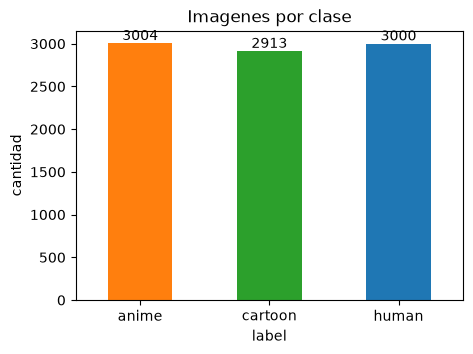

In [20]:
counts = df["label"].value_counts().reindex(CLASSES)
ax = counts.plot.bar(figsize=(5, 3.5), color=["tab:orange", "tab:green", "tab:blue"])
ax.bar_label(ax.containers[0])
ax.set_title("Imagenes por clase")
ax.set_ylabel("cantidad")
plt.xticks(rotation=0)
plt.show()

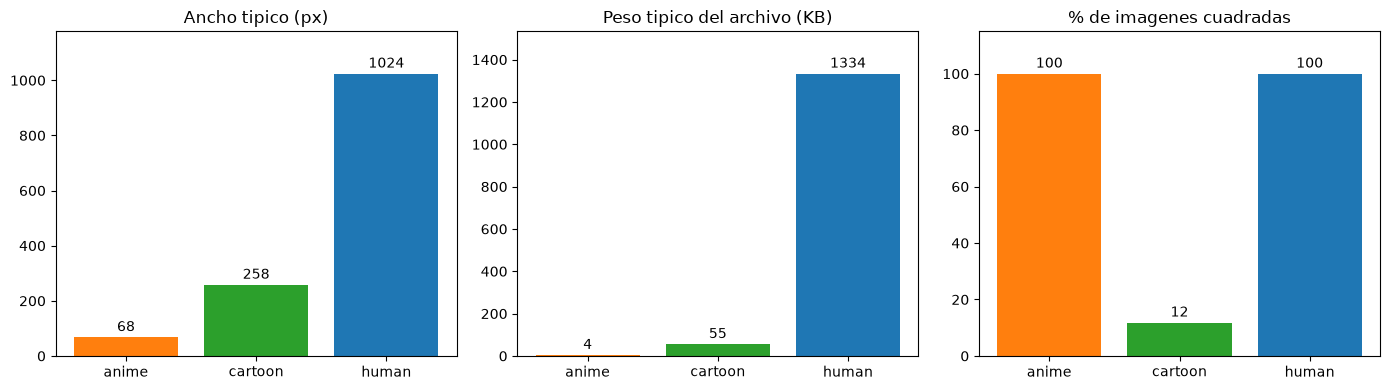

width               height               aspect              size_kb  \
          min  median   max    min  median   max    min median   max     min   
label                                                                          
anime      25    68.0   189     25    68.0   189   1.00   1.00  1.02    1.21   
cartoon    74   258.0   519     77   180.0   315   0.37   1.34  5.35    2.95   
human    1024  1024.0  1024   1024  1024.0  1024   1.00   1.00  1.00  595.76   

                           
          median      max  
label                      
anime       4.21    23.92  
cartoon    55.44   133.23  
human    1333.76  2057.71

In [28]:
# Resolucion y peso de archivo por clase: valor tipico (mediana) de cada clase
df["aspect"] = (df["width"] / df["height"]).astype(float)
df["square"] = (df["aspect"] - 1).abs() < 0.05   # casi cuadrada (+-5%)
COLORS = {"anime": "tab:orange", "cartoon": "tab:green", "human": "tab:blue"}

summary = pd.DataFrame({
    "Ancho tipico (px)": df.groupby("label")["width"].median().astype(float),
    "Peso tipico del archivo (KB)": df.groupby("label")["size_kb"].median(),
    "% de imagenes cuadradas": df.groupby("label")["square"].mean() * 100,
}).reindex(CLASSES)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, summary.columns):
    bars = ax.bar(CLASSES, summary[col], color=[COLORS[c] for c in CLASSES])
    ax.bar_label(bars, fmt="%.0f", padding=2)
    ax.set_title(col)
    ax.set_ylim(0, summary[col].max() * 1.15)
plt.tight_layout()
plt.show()

display(df.groupby("label")[["width", "height", "aspect", "size_kb"]].agg(["min", "median", "max"]).round(2))

In [22]:
# Modo de color y formato por clase
display(pd.crosstab(df["label"], df["mode"]))
display(pd.crosstab(df["label"], df["format"]))

# Las imagenes RGBA / P: tienen transparencia real? (si no, convert("RGB") es seguro)
def has_transparency(fp):
    with Image.open(fp) as im:
        alpha = np.asarray(im.convert("RGBA"))[..., 3]
    return bool((alpha < 255).any())

non_rgb = df[df["mode"] != "RGB"]
n_transp = sum(has_transparency(f) for f in non_rgb["filepath"])
print(f"Imagenes no RGB: {len(non_rgb)} | con transparencia real: {n_transp}")

mode,P,RGB,RGBA
label,,,
anime,0,3004,0
cartoon,74,653,2186
human,0,3000,0


format,JPEG,PNG
label,,
anime,3004,0
cartoon,653,2260
human,0,3000


Imagenes no RGB: 2260 | con transparencia real: 0


In [23]:
# Duplicados exactos (mismo contenido de archivo)
df["md5"] = [hashlib.md5(Path(f).read_bytes()).hexdigest() for f in df["filepath"]]

dups = df[df.duplicated("md5", keep=False)]
print("Imagenes involucradas en duplicados:", len(dups), "| grupos:", dups["md5"].nunique())
print("Grupos que mezclan clases:", (dups.groupby("md5")["label"].nunique() > 1).sum())

extra = df[df.duplicated("md5", keep="first")]
print("\nImagenes sobrantes por clase si se deduplica:")
print(extra["label"].value_counts())

df_unique = df.drop_duplicates("md5").reset_index(drop=True)
print("\nConteo por clase tras deduplicar:")
print(df_unique["label"].value_counts())

Imagenes involucradas en duplicados: 712 | grupos: 329
Grupos que mezclan clases: 0

Imagenes sobrantes por clase si se deduplica:
label
anime    383
Name: count, dtype: int64

Conteo por clase tras deduplicar:
label
human      3000
cartoon    2913
anime      2621
Name: count, dtype: int64


Tamano de los grupos duplicados: {2: 286, 3: 36, 4: 3, 5: 4}


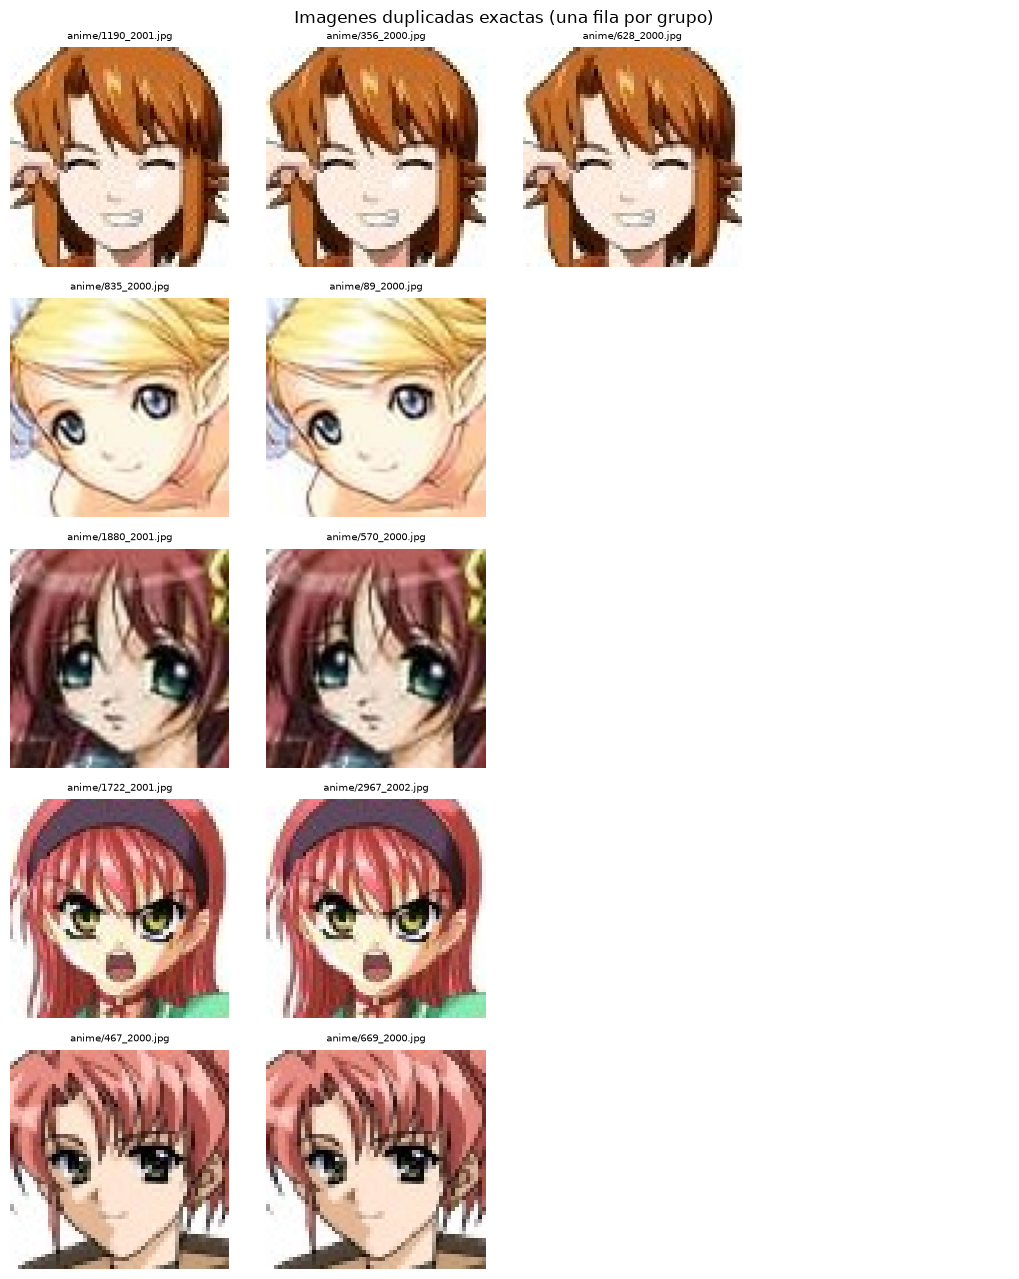

In [24]:
# Ejemplos de grupos duplicados: cada fila es un grupo, cada columna una copia
N_GROUPS, MAX_COPIES = 5, 4
groups = dups.groupby("md5").size().sort_values(ascending=False)
print("Tamano de los grupos duplicados:", groups.value_counts().sort_index().to_dict())

sample_md5 = groups.sample(N_GROUPS, random_state=SEED).index
fig, axes = plt.subplots(N_GROUPS, MAX_COPIES, figsize=(2.6 * MAX_COPIES, 2.6 * N_GROUPS))
for i, h in enumerate(sample_md5):
    copies = dups[dups["md5"] == h].head(MAX_COPIES)
    for j in range(MAX_COPIES):
        ax = axes[i, j]
        ax.axis("off")
        if j < len(copies):
            r = copies.iloc[j]
            with Image.open(r["filepath"]) as im:
                ax.imshow(im.convert("RGB"))
            ax.set_title(f"{r['label']}/{Path(r['filepath']).name}", fontsize=7)
plt.suptitle("Imagenes duplicadas exactas (una fila por grupo)")
plt.tight_layout()
plt.show()

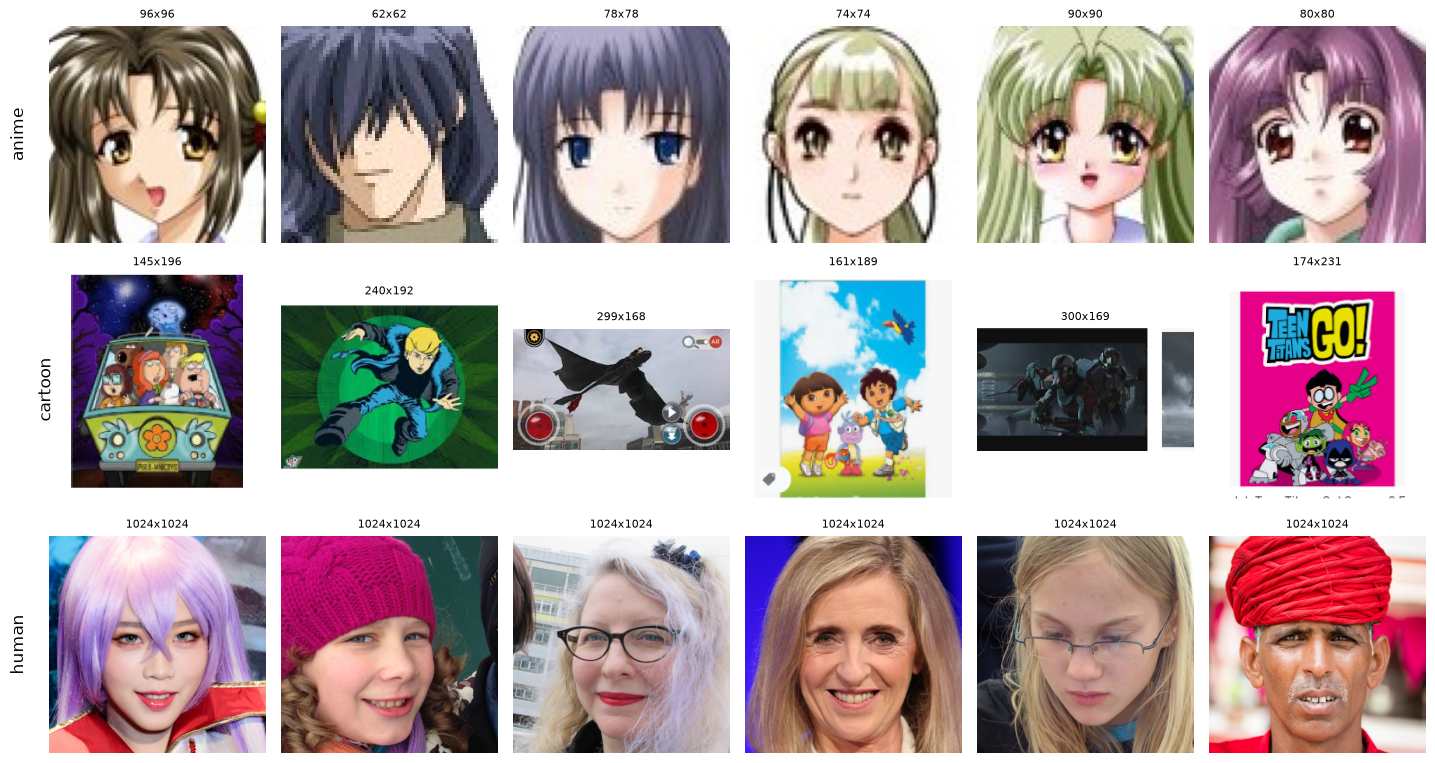

In [25]:
# Muestra aleatoria de imagenes por clase (el titulo indica la resolucion original)
N = 6
fig, axes = plt.subplots(len(CLASSES), N, figsize=(2.4 * N, 2.6 * len(CLASSES)))
for i, c in enumerate(CLASSES):
    for j, (_, r) in enumerate(df[df["label"] == c].sample(N, random_state=SEED).iterrows()):
        with Image.open(r["filepath"]) as im:
            axes[i, j].imshow(im.convert("RGB"))
        axes[i, j].set_title(f"{r['width']}x{r['height']}", fontsize=8)
        axes[i, j].axis("off")
    axes[i, 0].text(-0.1, 0.5, c, transform=axes[i, 0].transAxes, rotation=90,
                    va="center", ha="right", fontsize=12)
plt.tight_layout()
plt.show()

,R,G,B,std
label,,,,
anime,0.637497,0.544931,0.513575,0.276612
cartoon,0.609673,0.575152,0.549934,0.264825
human,0.520899,0.424424,0.377492,0.239252


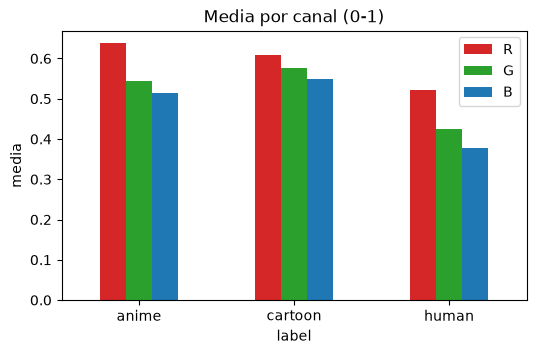

In [26]:
# Estadisticos de color sobre una muestra de 300 imagenes por clase, a 64x64
rows = []
for c in CLASSES:
    for f in df[df["label"] == c].sample(300, random_state=SEED)["filepath"]:
        with Image.open(f) as im:
            x = np.asarray(im.convert("RGB").resize((64, 64)), dtype=np.float32) / 255
        rows.append({"label": c, "R": x[..., 0].mean(), "G": x[..., 1].mean(),
                     "B": x[..., 2].mean(), "std": x.std()})

color_stats = pd.DataFrame(rows).groupby("label").mean()
display(color_stats)
color_stats[["R", "G", "B"]].plot.bar(color=["tab:red", "tab:green", "tab:blue"], figsize=(6, 3.5))
plt.title("Media por canal (0-1)")
plt.ylabel("media")
plt.xticks(rotation=0)
plt.show()

### Conclusiones del EDA

- **Balance:** clases casi balanceadas (2913 a 3004 por clase), por lo que accuracy es una métrica válida.
- **Integridad:** no hay archivos corruptos.
- **Resolución (riesgo de atajo):** anime son miniaturas (25–189 px, ~5 KB), cartoon es intermedio (74–519 px, ~50 KB) y human siempre es 1024×1024 (~1.3 MB). Un modelo podría clasificar por nitidez o resolución y no por contenido. Se mitiga redimensionando todo a un tamaño único y con aumento de datos.
- **Contenido:** anime y human son retratos de rostros recortados, mientras que cartoon incluye personajes de cuerpo completo, escenas y capturas con márgenes. El modelo puede apoyarse en la composición. Hay que revisar las imágenes mal clasificadas, por ejemplo humanos con estética anime.
- **Canales:** cartoon mezcla RGB (653), RGBA (2186) y paleta P (74). Ninguna imagen tiene transparencia real, así que `convert("RGB")` no altera el contenido.
- **Relación de aspecto:** anime y human son cuadradas; cartoon va de 0.37 a 5.35. Redimensionar directo a cuadrado deforma las cartoon, y hay que decidir entre estirar o rellenar (padding).
- **Duplicados:** hay 383 imágenes duplicadas exactas, todas de la clase anime y ninguna entre clases. Se eliminan **antes** de dividir en train/val/test para evitar fuga de datos. Tras deduplicar: human 3000, cartoon 2913, anime 2621 (desbalance leve).
- **Color:** human es en promedio más oscura (media de R, G y B de 0.52, 0.42 y 0.38) que anime (0.64, 0.54, 0.51) y cartoon (0.61, 0.58, 0.55). Es otra señal que el modelo podría aprovechar.
- **Normalización:** `Rescaling(1/255)` dentro de la CNN propia. EfficientNet incluye su propio preprocesamiento y espera valores en [0, 255].


## 4. ETL: transformacion y carga
Con base en el EDA se transforman los datos: se parten las rutas sin duplicados en entrenamiento, validacion y prueba (70/15/15, estratificado), y cada imagen se convierte a RGB y se deja en 128x128. Los arreglos resultantes (`uint8`) se guardan en una cache local para no volver a decodificar las imagenes originales.

`RESIZE_MODE` controla como se llega a un cuadrado: `"pad"` conserva la proporcion y rellena con el color del borde, y `"stretch"` estira la imagen. Se empieza con `"pad"` y despues se compara con `"stretch"`, ya que el padding puede introducir un atajo (las cartoon no cuadradas tendrian barras y las otras clases no). La division entre 255 se hace dentro del modelo, y el aumento de datos solo en entrenamiento.

In [ ]:
from concurrent.futures import ThreadPoolExecutor

from sklearn.model_selection import train_test_split

IMG_SIZE = 128
RESIZE_MODE = "pad"   # "pad": conserva la proporcion y rellena | "stretch": estira a cuadrado
CACHE_DIR = Path("cache") / f"{RESIZE_MODE}_{IMG_SIZE}"
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
print("Modo:", RESIZE_MODE, "| Tamano:", IMG_SIZE, "| Cache:", CACHE_DIR)
print("Clases -> indice:", CLASS_TO_IDX)

In [ ]:
# Particion estratificada 70/15/15 sobre las imagenes sin duplicados
df_unique["y"] = df_unique["label"].map(CLASS_TO_IDX)

train_df, rest_df = train_test_split(
    df_unique, test_size=0.30, stratify=df_unique["y"], random_state=SEED)
val_df, test_df = train_test_split(
    rest_df, test_size=0.50, stratify=rest_df["y"], random_state=SEED)
splits = {"train": train_df, "val": val_df, "test": test_df}

# Ninguna imagen (por contenido) puede estar en dos particiones
hashes = {name: set(d["md5"]) for name, d in splits.items()}
assert not (hashes["train"] & hashes["val"] or hashes["train"] & hashes["test"]
            or hashes["val"] & hashes["test"]), "hay fuga de datos entre particiones"

display(pd.DataFrame({name: d["label"].value_counts() for name, d in splits.items()})
        .reindex(CLASSES).assign(total=lambda t: t.sum(axis=1)))

In [ ]:
def edge_color(arr):
    """Color mediano del borde de la imagen, para rellenar sin crear barras llamativas."""
    border = np.concatenate([arr[0], arr[-1], arr[:, 0], arr[:, -1]])
    return np.median(border, axis=0).astype(np.uint8)


def preprocess(fp, size=IMG_SIZE, mode=RESIZE_MODE):
    """Abre la imagen, la pasa a RGB y la deja de size x size (uint8)."""
    with Image.open(fp) as im:
        im = im.convert("RGB")
        if mode == "stretch":
            return np.asarray(im.resize((size, size), Image.LANCZOS))
        scale = size / max(im.size)
        new_w, new_h = max(1, round(im.width * scale)), max(1, round(im.height * scale))
        small = np.asarray(im.resize((new_w, new_h), Image.LANCZOS))
    canvas = np.empty((size, size, 3), dtype=np.uint8)
    canvas[:] = edge_color(small)
    top, left = (size - new_h) // 2, (size - new_w) // 2
    canvas[top:top + new_h, left:left + new_w] = small
    return canvas


def build_split(name, d):
    """Devuelve (X, y) de una particion; si ya esta en cache la carga del disco."""
    out = CACHE_DIR / f"{name}.npz"
    if out.exists():
        z = np.load(out)
        return z["X"], z["y"]
    with ThreadPoolExecutor() as pool:
        X = np.stack(list(pool.map(preprocess, d["filepath"])))
    y = d["y"].to_numpy(np.int64)
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    np.savez(out, X=X, y=y)
    return X, y


data = {name: build_split(name, d) for name, d in splits.items()}
for name, (X, y) in data.items():
    print(f"{name:5s} X={X.shape} {X.dtype} | y={y.shape} | clases={np.bincount(y).tolist()}")

In [ ]:
# Verificacion visual: imagenes de entrenamiento ya transformadas
X_train, y_train = data["train"]
rng = np.random.default_rng(SEED)
N = 8
fig, axes = plt.subplots(len(CLASSES), N, figsize=(1.8 * N, 1.9 * len(CLASSES)))
for i, c in enumerate(CLASSES):
    idx = rng.choice(np.where(y_train == CLASS_TO_IDX[c])[0], N, replace=False)
    for j, k in enumerate(idx):
        axes[i, j].imshow(X_train[k])
        axes[i, j].axis("off")
    axes[i, 0].text(-0.1, 0.5, c, transform=axes[i, 0].transAxes, rotation=90,
                    va="center", ha="right", fontsize=11)
plt.suptitle(f"Entrenamiento tras la transformacion ({RESIZE_MODE}, {IMG_SIZE}x{IMG_SIZE})")
plt.tight_layout()
plt.show()

print("Rango de pixeles:", X_train.min(), "-", X_train.max(), "| memoria train: %.0f MB" % (X_train.nbytes / 1e6))